# 🏨 Hotel Revenue Protection: Booking Cancellation Predictor
**NextGen Institute · Machine Learning · Final Project (Idea #10)**

Dataset: *Hotel Booking Demand* (Antonio, Almeida & Nunes, 2019) — real bookings from two Portuguese hotels (a city hotel and a resort), 2015-07 → 2017-08.
Source: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

---
## 1 · Problem framing
- **Who has the problem?** Hotel revenue managers. A cancelled room that is not re-sold is lost revenue; overbooking too much means walking guests.
- **Decision the model supports:** for each booking, how risky is it → what **deposit policy** to apply (no deposit / partial / full) and how aggressively to overbook.
- **Target:** `is_canceled` (1 = cancelled / no-show, 0 = stayed).
- **Metric that matters:** *missing* a cancellation (false negative) costs an empty room; *wrongly flagging* a good booking (false positive) costs goodwill or a lost booking. So we track **ROC-AUC** (ranking quality), **PR-AUC**, and **recall / precision / F1 of the cancel class** — accuracy alone is misleading with ~27 % positives.
- **Prediction time:** any moment before arrival, using only information the hotel already has (no check-in or outcome information).

In [1]:
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns, joblib, json, os, time
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, GridSearchCV, cross_val_predict, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score, recall_score,
                             accuracy_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
                             PrecisionRecallDisplay, classification_report, precision_recall_curve)
from sklearn.inspection import permutation_importance
from hotel_features import build_features, NUM_FEATURES, CAT_FEATURES, LEAKAGE_COLS, EXCLUDED_COLS, MONTHS

SEED = 42
sns.set_theme(style='whitegrid', context='notebook')
os.makedirs('figures', exist_ok=True)
DATA = 'hotel_bookings.csv'   # download from the Kaggle link above and put it next to this notebook
raw = pd.read_csv(DATA)
raw.shape

(119390, 32)

## 2 · Data understanding

In [2]:
print(f"Rows: {raw.shape[0]:,}  |  Columns: {raw.shape[1]}")
print(f"Period: {raw.arrival_date_year.min()} → {raw.arrival_date_year.max()}  |  Hotels: {raw.hotel.unique().tolist()}")
raw.head()

Rows: 119,390  |  Columns: 32
Period: 2015 → 2017  |  Hotels: ['Resort Hotel', 'City Hotel']


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


**Column dictionary (main groups)**

| Group | Columns | Notes |
|---|---|---|
| Target | `is_canceled` | 1 = cancelled |
| Booking | `hotel`, `lead_time`, `market_segment`, `distribution_channel`, `agent`, `company`, `customer_type`, `deposit_type`, `days_in_waiting_list` | `lead_time` = days between booking and arrival |
| Stay | `arrival_date_*`, `stays_in_weekend_nights`, `stays_in_week_nights`, `meal`, `reserved_room_type` | |
| Guests | `adults`, `children`, `babies`, `country`, `is_repeated_guest`, `previous_cancellations`, `previous_bookings_not_canceled` | |
| Money / service | `adr` (average daily rate), `required_car_parking_spaces`, `total_of_special_requests` | parking is a leakage field — see section 4 |
| ⚠️ Known only after the outcome | `reservation_status`, `reservation_status_date`, `assigned_room_type`, `booking_changes` | **leakage candidates** — see section 4 |

In [3]:
info = pd.DataFrame({'dtype': raw.dtypes.astype(str), 'missing': raw.isna().sum(), 'missing_%': (raw.isna().mean()*100).round(2), 'n_unique': raw.nunique()})
display(info)
print("\nString 'NULL' placeholders:", {c: int((raw[c]=='NULL').sum()) for c in raw.columns if raw[c].dtype==object or str(raw[c].dtype)=='str' if (raw[c]=='NULL').sum()>0})
print(f"\nExact duplicate rows: {raw.duplicated().sum():,} ({raw.duplicated().mean():.1%})")
print("Class balance (raw):"); print(raw.is_canceled.value_counts(normalize=True).round(3))

,dtype,missing,missing_%,n_unique
hotel,str,0,0.00,2
is_canceled,int64,0,0.00,2
lead_time,int64,0,0.00,479
arrival_date_year,int64,0,0.00,3
arrival_date_month,str,0,0.00,12
arrival_date_week_number,int64,0,0.00,53
arrival_date_day_of_month,int64,0,0.00,31
stays_in_weekend_nights,int64,0,0.00,17
stays_in_week_nights,int64,0,0.00,35
adults,int64,0,0.00,14



String 'NULL' placeholders: {}



Exact duplicate rows: 31,994 (26.8%)
Class balance (raw):
is_canceled
0    0.63
1    0.37
Name: proportion, dtype: float64


### Cleaning decisions
- **Exact duplicate rows are removed.** Identical bookings would otherwise land in both train and test and inflate scores.
- Rows with **zero guests** are removed (not real stays).
- `children` has 4 missing values → 0; `country` missing → `Unknown`; `agent` / `company` are mostly empty IDs → converted into `has_agent` / `has_company` flags (IDs themselves are anonymous codes).
- `adr` negative values / extreme outliers → clipped to [0, 1000] (inside the pipeline).

In [4]:
df = raw.drop_duplicates().copy()
df = df[(df.adults + df.children.fillna(0) + df.babies) > 0].reset_index(drop=True)
print(f"After cleaning: {df.shape[0]:,} rows (removed {raw.shape[0]-df.shape[0]:,})")
print(f"Cancellation rate after cleaning: {df.is_canceled.mean():.1%}")

After cleaning: 87,230 rows (removed 32,160)
Cancellation rate after cleaning: 27.5%


## 3 · Exploratory data analysis

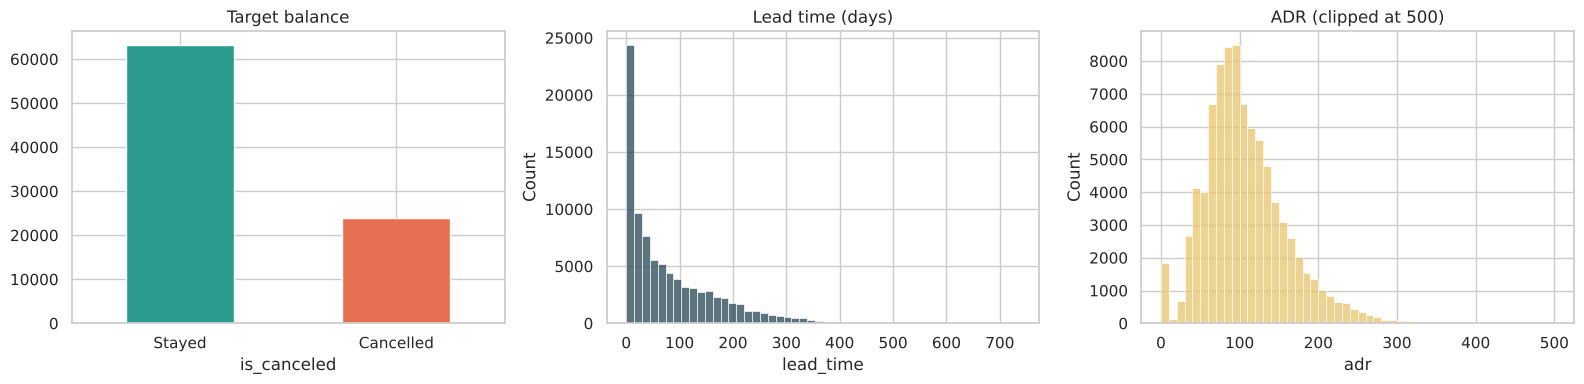

       lead_time      adr  stays_in_week_nights  stays_in_weekend_nights  \
count    87230.0  87230.0               87230.0                  87230.0   
mean        80.0    106.5                   2.6                      1.0   
std         86.1     54.9                   2.0                      1.0   
min          0.0     -6.4                   0.0                      0.0   
25%         11.0     72.2                   1.0                      0.0   
50%         49.0     98.2                   2.0                      1.0   
75%        125.0    134.1                   4.0                      2.0   
max        737.0   5400.0                  50.0                     19.0   

       previous_cancellations  
count                 87230.0  
mean                      0.0  
std                       0.4  
min                       0.0  
25%                       0.0  
50%                       0.0  
75%                       0.0  
max                      26.0  


In [5]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
df.is_canceled.value_counts().rename({0:'Stayed',1:'Cancelled'}).plot.bar(ax=ax[0], color=['#2a9d8f','#e76f51'], rot=0); ax[0].set_title('Target balance')
sns.histplot(df.lead_time, bins=50, ax=ax[1], color='#264653'); ax[1].set_title('Lead time (days)')
sns.histplot(df.adr.clip(0,500), bins=50, ax=ax[2], color='#e9c46a'); ax[2].set_title('ADR (clipped at 500)')
plt.tight_layout(); plt.savefig('figures/01_univariate.png', dpi=130); plt.show()
print(df[['lead_time','adr','stays_in_week_nights','stays_in_weekend_nights','previous_cancellations']].describe().round(1))

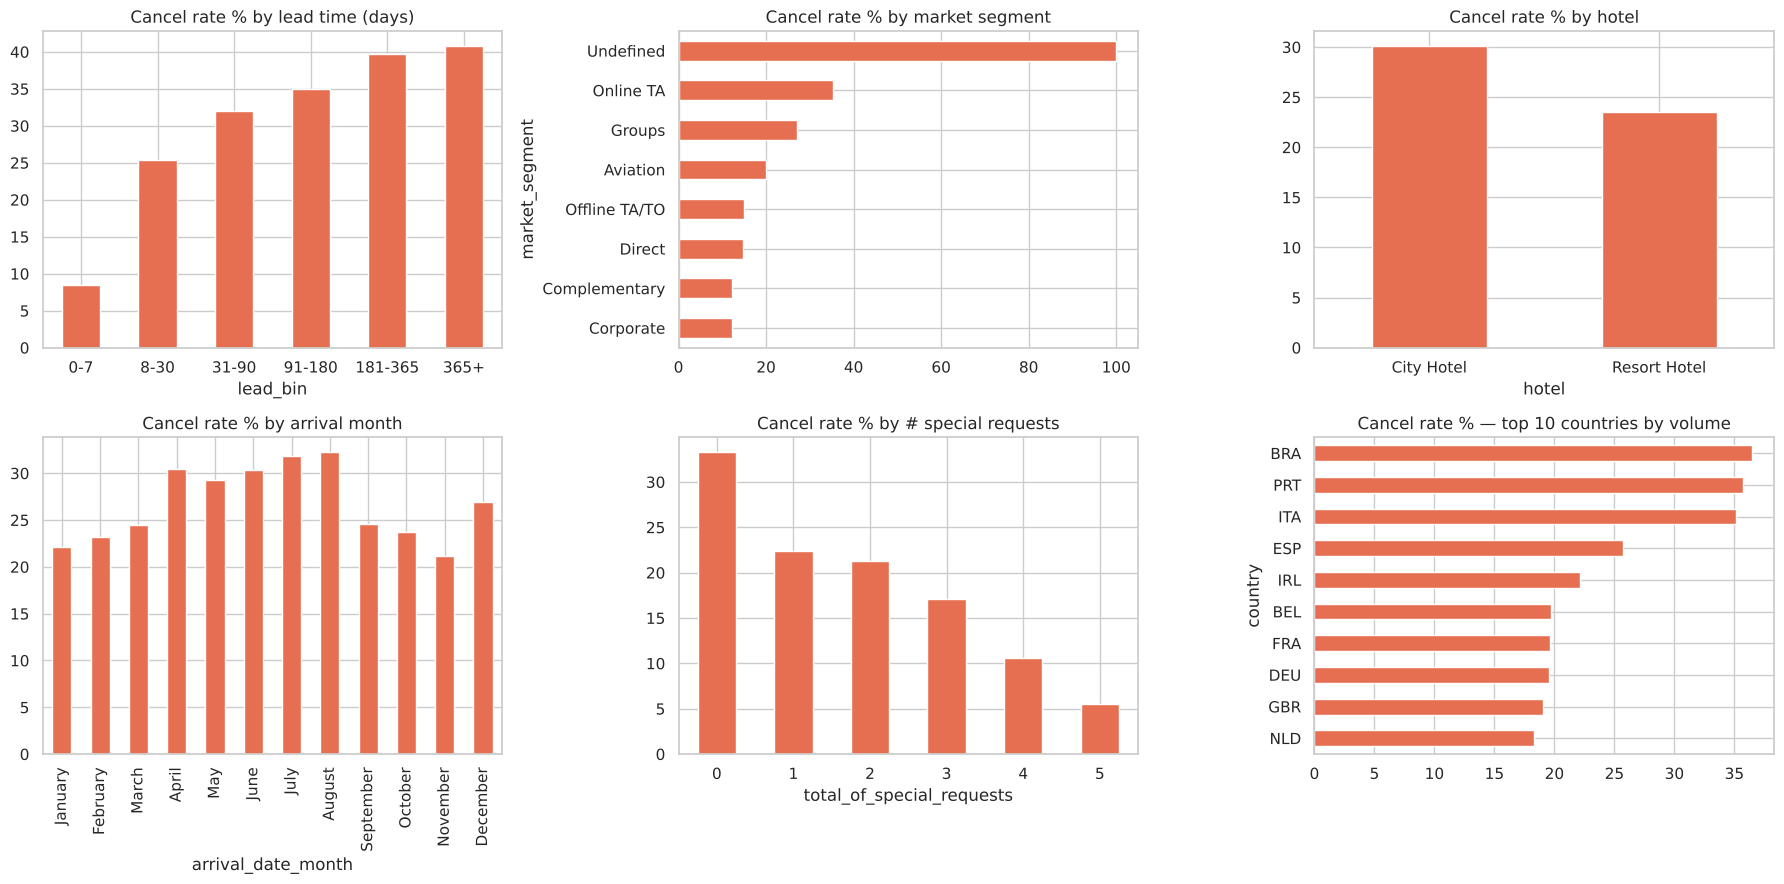

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(18, 9))
d = df.copy()
d['lead_bin'] = pd.cut(d.lead_time, [-1,7,30,90,180,365,1000], labels=['0-7','8-30','31-90','91-180','181-365','365+'])
d.groupby('lead_bin', observed=True).is_canceled.mean().mul(100).plot.bar(ax=ax[0,0], color='#e76f51', rot=0); ax[0,0].set_title('Cancel rate % by lead time (days)')
d.groupby('market_segment').is_canceled.mean().mul(100).sort_values().plot.barh(ax=ax[0,1], color='#e76f51'); ax[0,1].set_title('Cancel rate % by market segment')
d.groupby('hotel').is_canceled.mean().mul(100).plot.bar(ax=ax[0,2], color='#e76f51', rot=0); ax[0,2].set_title('Cancel rate % by hotel')
d.groupby('arrival_date_month').is_canceled.mean().reindex(MONTHS).mul(100).plot.bar(ax=ax[1,0], color='#e76f51'); ax[1,0].set_title('Cancel rate % by arrival month')
d.groupby('total_of_special_requests').is_canceled.mean().mul(100).plot.bar(ax=ax[1,1], color='#e76f51', rot=0); ax[1,1].set_title('Cancel rate % by # special requests')
top = d.country.value_counts().head(10).index
d[d.country.isin(top)].groupby('country').is_canceled.mean().mul(100).sort_values().plot.barh(ax=ax[1,2], color='#e76f51'); ax[1,2].set_title('Cancel rate % — top 10 countries by volume')
plt.tight_layout(); plt.savefig('figures/02_bivariate.png', dpi=130); plt.show()

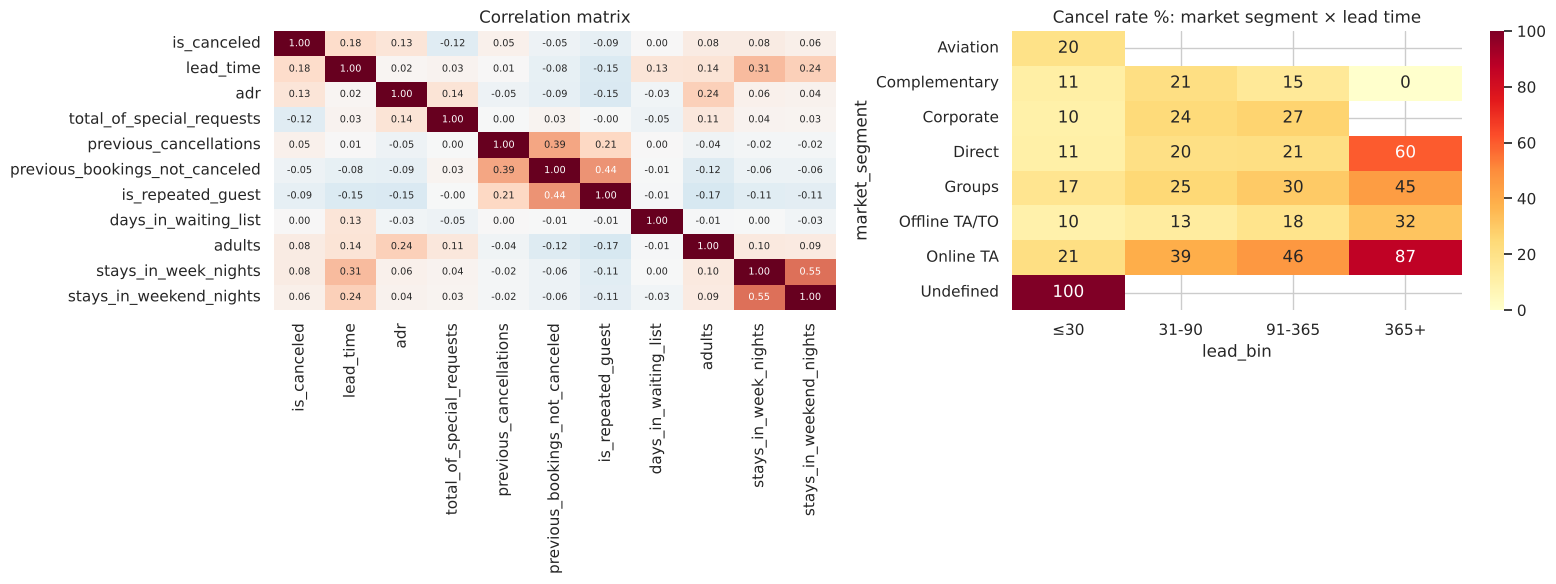

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
num = ['is_canceled','lead_time','adr','total_of_special_requests','previous_cancellations',
       'previous_bookings_not_canceled','is_repeated_guest','days_in_waiting_list','adults','stays_in_week_nights','stays_in_weekend_nights']
sns.heatmap(df[num].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0, ax=ax[0], cbar=False, annot_kws={'size':7}); ax[0].set_title('Correlation matrix')
x = df.assign(lead_bin=pd.cut(df.lead_time,[-1,30,90,365,1000],labels=['≤30','31-90','91-365','365+']))
piv = x.pivot_table(index='market_segment', columns='lead_bin', values='is_canceled', aggfunc='mean', observed=True).mul(100)
sns.heatmap(piv, annot=True, fmt='.0f', cmap='YlOrRd', ax=ax[1]); ax[1].set_title('Cancel rate %: market segment × lead time')
plt.tight_layout(); plt.savefig('figures/03_multivariate.png', dpi=130); plt.show()

In [8]:
s = {}
lb = d.groupby('lead_bin', observed=True).is_canceled.mean()
ms = d.groupby('market_segment').is_canceled.agg(['mean','size']).query('size>500')
print(f"Lead time:   {lb.iloc[0]:.1%} cancel for 0-7 days  →  {lb.iloc[-1]:.1%} for 365+ days")
print("Market segment (n>500):"); print((ms['mean']*100).round(1).sort_values(ascending=False).to_string())
sr = d.groupby(d.total_of_special_requests>0).is_canceled.mean()
print(f"Special requests: {sr[False]:.1%} cancel with none vs {sr[True]:.1%} with ≥1")
pc = d.groupby(d.previous_cancellations>0).is_canceled.agg(['mean','size']); print("Previous cancellations (False/True):"); print(pc.round(3).to_string())
ht = d.groupby('hotel').is_canceled.mean(); print(ht.round(3).to_dict())
rg = d.groupby('is_repeated_guest').is_canceled.mean(); print(f"Repeat guest: {rg[1]:.1%} vs new {rg[0]:.1%}")

Lead time:   8.4% cancel for 0-7 days  →  40.8% for 365+ days
Market segment (n>500):
market_segment
Online TA        35.4
Groups           27.1
Offline TA/TO    14.8
Direct           14.7
Complementary    12.3
Corporate        12.1
Special requests: 33.3% cancel with none vs 21.7% with ≥1
Previous cancellations (False/True):
                         mean   size
previous_cancellations              
False                   0.267  85549
True                    0.680   1681
{'City Hotel': 0.301, 'Resort Hotel': 0.235}
Repeat guest: 7.7% vs new 28.3%


### 💡 EDA insights
1. **Lead time is the strongest simple signal.** Cancellation climbs from 8.4 % for bookings made 0–7 days ahead to 40.8 % for bookings made a year or more ahead — far-ahead bookings are "options", not commitments.
2. **Online travel agencies are the risky channel.** Online TA bookings cancel 35.4 % of the time vs. 14.7 % for Direct and 12.1 % for Corporate. *Hypothesis:* free-cancellation online bookings are often made to hold a price while the guest keeps comparing.
3. **Loyalty and history matter.** Repeat guests cancel 7.7 % vs. 28.3 % for new guests; guests with a previous cancellation cancel 68.0 % vs. 26.7 %.
4. **Engaged guests stay.** Bookings with at least one special request cancel 21.7 % vs. 33.3 % with none.
5. **City Hotel is riskier than the Resort** (30.1 % vs. 23.5 %), and the segment × lead-time heatmap shows the effects compound (long lead time *and* Online TA is the worst corner).

## 4 · Leakage check (why some columns are dropped)

In [9]:
print("Outcome vs reservation_status:"); print(pd.crosstab(df.reservation_status, df.is_canceled))
print("\nCancel rate by deposit_type:"); print(df.groupby('deposit_type').is_canceled.agg(['mean','size']).round(3))
pk = df.groupby(df.required_car_parking_spaces>0).is_canceled.agg(['mean','size']); print("\nCancel rate by parking requested (False/True):"); print(pk.round(4))
print("Cancel rate by booking_changes>0 (False/True):"); print(df.groupby(df.booking_changes>0).is_canceled.mean().round(3).to_dict())

Outcome vs reservation_status:
is_canceled             0      1
reservation_status              
Canceled                0  22996
Check-Out           63221      0
No-Show                 0   1013

Cancel rate by deposit_type:
               mean   size
deposit_type              
No Deposit    0.267  86085
Non Refund    0.947   1038
Refundable    0.243    107

Cancel rate by parking requested (False/True):
                               mean   size
required_car_parking_spaces               
False                        0.3004  79924
True                         0.0000   7306
Cancel rate by booking_changes>0 (False/True):
{False: 0.302, True: 0.155}


- `reservation_status` / `reservation_status_date` **are the outcome itself** (Canceled / No-Show ⇒ `is_canceled = 1`; Check-Out ⇒ 0) → removed.
- `assigned_room_type` is set at check-in, `booking_changes` keeps growing after the booking is made → not available when predicting → removed.
- `required_car_parking_spaces`: **0 % of bookings with a parking space were cancelled** — the field is only filled for guests who actually arrive, so it leaks the outcome. This was spotted when it showed up as a top feature in a first model run, then removed.
- `arrival_date_year` is not used as a feature: a model keyed on the year cannot generalise to a new year (month / week / weekday are kept for seasonality).
- `deposit_type`: "Non Refund" bookings are ~95 % cancelled. That is a **data artefact** (mostly group/agent bookings in Portugal), and it is also the **policy we want to recommend** — using it as an input would be circular. We measure how much it would inflate the score:

In [10]:
y_all = df.is_canceled; X_all = df.drop(columns='is_canceled')
Xa, Xb, ya, yb = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
def quick_auc(extra_cat):
    cats = CAT_FEATURES + extra_cat
    def fe(d):
        out = build_features(d)
        for c in extra_cat: out[c] = d[c].values
        return out
    pre = ColumnTransformer([('n', SimpleImputer(strategy='median'), NUM_FEATURES),
        ('c', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01, sparse_output=False), cats)])
    p = Pipeline([('fe', FunctionTransformer(fe)), ('pre', pre), ('m', HistGradientBoostingClassifier(random_state=SEED))]).fit(Xa, ya)
    return roc_auc_score(yb, p.predict_proba(Xb)[:,1])
print(f"ROC-AUC without deposit_type: {quick_auc([]):.4f}")
print(f"ROC-AUC with    deposit_type: {quick_auc(['deposit_type']):.4f}   ← (shown only for comparison; not used)")

ROC-AUC without deposit_type: 0.8752


ROC-AUC with    deposit_type: 0.8771   ← (shown only for comparison; not used)


## 5 · Preprocessing & pipeline (no leakage)
Everything below lives **inside one scikit-learn `Pipeline`**, fitted on the training split only:
1. `build_features` (in `hotel_features.py`): total nights, guests, family flag, ADR per person, special-request flag, agent/company flags, month (also cyclical sin/cos), weekday of arrival, ADR clipping.
2. `ColumnTransformer`: numeric → median imputation + scaling; categoricals → one-hot with rare levels (< 1 %) grouped into an "infrequent" bucket — this handles the high-cardinality `country` without fitting anything on the test set.

We split **80 / 20, stratified**, *before* fitting anything.

In [11]:
y = df.is_canceled; X = df.drop(columns=['is_canceled'] + LEAKAGE_COLS + EXCLUDED_COLS)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(f"Train: {X_train.shape}  cancel rate {y_train.mean():.3f}  |  Test: {X_test.shape}  cancel rate {y_test.mean():.3f}")

def make_pipe(model):
    pre = ColumnTransformer([
        ('num', Pipeline([('imp', SimpleImputer(strategy='median')), ('sc', StandardScaler())]), NUM_FEATURES),
        ('cat', OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=0.01, sparse_output=False), CAT_FEATURES)])
    return Pipeline([('fe', FunctionTransformer(build_features)), ('pre', pre), ('model', model)])
cv = StratifiedKFold(5, shuffle=True, random_state=SEED)

Train: (69784, 25)  cancel rate 0.275  |  Test: (17446, 25)  cancel rate 0.275


## 6 · Modeling — baseline + 3 algorithms, then tuning

In [12]:
candidates = {
  'Baseline (majority class)': DummyClassifier(strategy='most_frequent'),
  'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced'),
  'Random Forest': RandomForestClassifier(n_estimators=150, min_samples_leaf=3, max_samples=0.5, n_jobs=-1, class_weight='balanced_subsample', random_state=SEED),
  'Gradient Boosting (HistGB)': HistGradientBoostingClassifier(random_state=SEED),
}
rows = []
for name, m in candidates.items():
    t = time.time()
    s = cross_val_score(make_pipe(m), X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=1)
    rows.append({'model': name, 'CV ROC-AUC (mean)': s.mean(), 'std': s.std(), 'sec': time.time()-t}); print(rows[-1])
pd.DataFrame(rows).round(4)

{'model': 'Baseline (majority class)', 'CV ROC-AUC (mean)': np.float64(0.5), 'std': np.float64(0.0), 'sec': 2.8003733158111572}


{'model': 'Logistic Regression', 'CV ROC-AUC (mean)': np.float64(0.8054093691028094), 'std': np.float64(0.0019708708813431057), 'sec': 4.370622873306274}


{'model': 'Random Forest', 'CV ROC-AUC (mean)': np.float64(0.8709722845496966), 'std': np.float64(0.0012152068515507615), 'sec': 35.65740942955017}


{'model': 'Gradient Boosting (HistGB)', 'CV ROC-AUC (mean)': np.float64(0.8678108250872466), 'std': np.float64(0.0013198947876421605), 'sec': 15.321252822875977}


,model,CV ROC-AUC (mean),std,sec
0,Baseline (majority class),0.5000,0.0000,2.8004
1,Logistic Regression,0.8054,0.0020,4.3706
2,Random Forest,0.8710,0.0012,35.6574
3,Gradient Boosting (HistGB),0.8678,0.0013,15.3213


In [13]:
# Hyperparameter tuning — training data only, 3-fold CV, optimising ROC-AUC
searches = {}
t = time.time()
searches['Logistic Regression'] = GridSearchCV(make_pipe(LogisticRegression(max_iter=1000, class_weight='balanced')),
    {'model__C': [0.01, 0.1, 1, 10]}, cv=3, scoring='roc_auc', n_jobs=1).fit(X_train, y_train)
print('LR  done', round(time.time()-t), 's  best', searches['Logistic Regression'].best_params_, round(searches['Logistic Regression'].best_score_, 4))
t = time.time()
searches['Random Forest'] = RandomizedSearchCV(make_pipe(RandomForestClassifier(n_estimators=150, max_samples=0.5, n_jobs=-1, class_weight='balanced_subsample', random_state=SEED)),
    {'model__max_depth': [12, 18, 25, None], 'model__min_samples_leaf': [1, 3, 5, 10], 'model__max_features': ['sqrt', 0.3, 0.5]},
    n_iter=6, cv=3, scoring='roc_auc', n_jobs=1, random_state=SEED).fit(X_train, y_train)
print('RF  done', round(time.time()-t), 's  best', searches['Random Forest'].best_params_, round(searches['Random Forest'].best_score_, 4))
t = time.time()
searches['Gradient Boosting (HistGB)'] = RandomizedSearchCV(make_pipe(HistGradientBoostingClassifier(random_state=SEED)),
    {'model__learning_rate': [0.03, 0.05, 0.1, 0.15], 'model__max_leaf_nodes': [15, 31, 63], 'model__min_samples_leaf': [20, 50, 100],
     'model__l2_regularization': [0, 0.1, 1.0], 'model__max_iter': [200, 400]},
    n_iter=8, cv=3, scoring='roc_auc', n_jobs=1, random_state=SEED).fit(X_train, y_train)
print('HGB done', round(time.time()-t), 's  best', searches['Gradient Boosting (HistGB)'].best_params_, round(searches['Gradient Boosting (HistGB)'].best_score_, 4))

LR  done 10 s  best {'model__C': 0.1} 0.8055


RF  done 150 s  best {'model__min_samples_leaf': 1, 'model__max_features': 0.3, 'model__max_depth': None} 0.8716


HGB done 128 s  best {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 63, 'model__max_iter': 400, 'model__learning_rate': 0.05, 'model__l2_regularization': 1.0} 0.8724


## 7 · Final evaluation on the untouched test set

In [14]:
def metrics(y_true, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {'ROC-AUC': roc_auc_score(y_true, proba), 'PR-AUC': average_precision_score(y_true, proba),
            'Accuracy': accuracy_score(y_true, pred), 'Precision': precision_score(y_true, pred, zero_division=0),
            'Recall': recall_score(y_true, pred), 'F1': f1_score(y_true, pred)}
res = {}
base = make_pipe(DummyClassifier(strategy='most_frequent')).fit(X_train, y_train)
res['Baseline (majority class)'] = metrics(y_test, base.predict_proba(X_test)[:,1])
for n, s in searches.items():
    res[n + ' (tuned)'] = metrics(y_test, s.best_estimator_.predict_proba(X_test)[:,1])
results = pd.DataFrame(res).T.round(4); results

,ROC-AUC,PR-AUC,Accuracy,Precision,Recall,F1
Baseline (majority class),0.5000,0.2752,0.7248,0.0000,0.0000,0.0000
Logistic Regression (tuned),0.8161,0.6313,0.7356,0.5135,0.7501,0.6096
Random Forest (tuned),0.8824,0.7457,0.8252,0.7247,0.5883,0.6494
Gradient Boosting (HistGB) (tuned),0.8845,0.7535,0.8245,0.7217,0.5902,0.6493


In [15]:
best_name = max(searches, key=lambda k: searches[k].best_score_)     # chosen on CV score, NOT on test score
best = searches[best_name].best_estimator_
print('Selected by cross-validation:', best_name, '| CV ROC-AUC', round(searches[best_name].best_score_, 4))
# decision threshold chosen on out-of-fold predictions of the TRAIN set (maximise F1) — test set stays untouched
oof = cross_val_predict(best, X_train, y_train, cv=cv, method='predict_proba')[:,1]
p, r, th = precision_recall_curve(y_train, oof); f1s = 2*p*r/(p+r+1e-9)
THR = float(th[np.argmax(f1s[:-1])]); print(f'Decision threshold (from train OOF, max F1): {THR:.3f}')
proba = best.predict_proba(X_test)[:,1]; pred = (proba >= THR).astype(int)
print(pd.Series(metrics(y_test, proba, THR)).round(4).to_string()); print(); print(classification_report(y_test, pred, target_names=['Stayed','Cancelled']))

Selected by cross-validation: Gradient Boosting (HistGB) | CV ROC-AUC 0.8724


Decision threshold (from train OOF, max F1): 0.317


ROC-AUC      0.8845
PR-AUC       0.7535
Accuracy     0.8068
Precision    0.6175
Recall       0.7834
F1           0.6907

              precision    recall  f1-score   support

      Stayed       0.91      0.82      0.86     12644
   Cancelled       0.62      0.78      0.69      4802

    accuracy                           0.81     17446
   macro avg       0.76      0.80      0.78     17446
weighted avg       0.83      0.81      0.81     17446



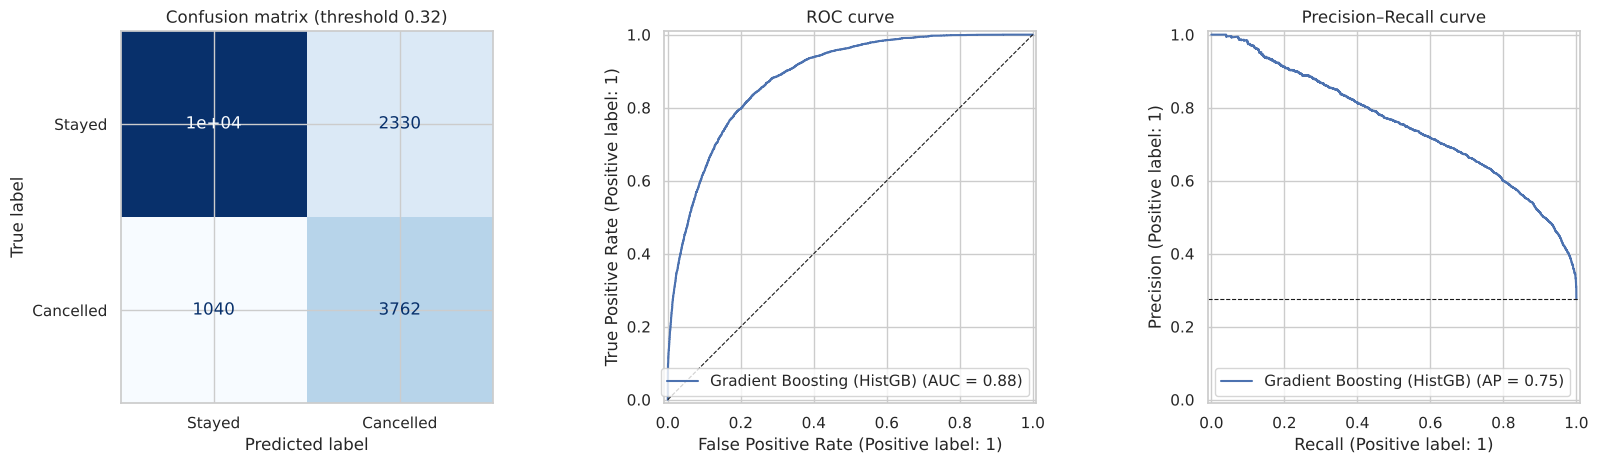

In [16]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.8))
ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['Stayed','Cancelled']).plot(ax=ax[0], cmap='Blues', colorbar=False); ax[0].set_title(f'Confusion matrix (threshold {THR:.2f})')
RocCurveDisplay.from_predictions(y_test, proba, ax=ax[1], name=best_name); ax[1].plot([0,1],[0,1],'k--', lw=.8); ax[1].set_title('ROC curve')
PrecisionRecallDisplay.from_predictions(y_test, proba, ax=ax[2], name=best_name); ax[2].axhline(y_test.mean(), color='k', ls='--', lw=.8); ax[2].set_title('Precision–Recall curve')
plt.tight_layout(); plt.savefig('figures/04_evaluation.png', dpi=130); plt.show()

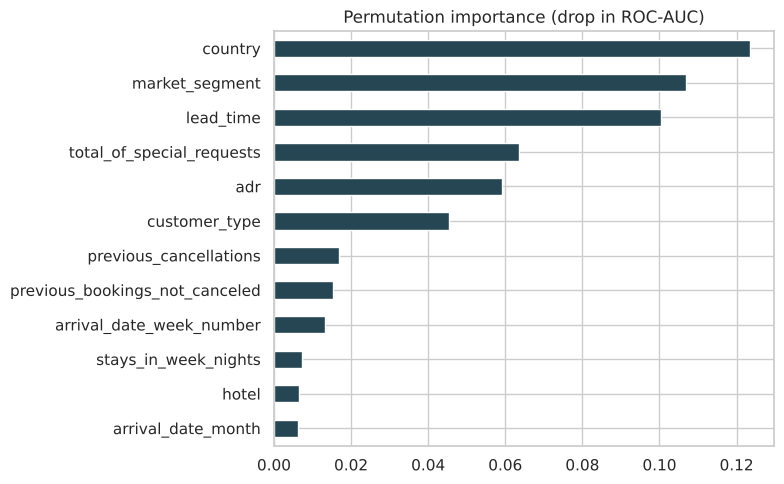

country                           0.1235
market_segment                    0.1070
lead_time                         0.1003
total_of_special_requests         0.0634
adr                               0.0591
customer_type                     0.0454
previous_cancellations            0.0168
previous_bookings_not_canceled    0.0154
dtype: float64

In [17]:
# Which features drive predictions? (permutation importance, 6k test rows)
idx = np.random.RandomState(SEED).choice(len(X_test), 6000, replace=False)
pi = permutation_importance(best, X_test.iloc[idx], y_test.iloc[idx], scoring='roc_auc', n_repeats=3, random_state=SEED, n_jobs=1)
imp = pd.Series(pi.importances_mean, index=X_test.columns).sort_values(ascending=False)
raw_cols_imp = imp.head(12)[::-1]
raw_cols_imp.plot.barh(figsize=(8,5), color='#264653'); plt.title('Permutation importance (drop in ROC-AUC)'); plt.tight_layout(); plt.savefig('figures/05_importance.png', dpi=130); plt.show()
imp.head(8).round(4)

In [18]:
# Error analysis
ea = X_test.copy(); ea['y'] = y_test.values; ea['pred'] = pred; ea['proba'] = proba
ea['type'] = np.select([(ea.y==1)&(ea.pred==0), (ea.y==0)&(ea.pred==1), (ea.y==1)&(ea.pred==1)], ['FN (missed cancel)','FP (false alarm)','TP'], 'TN')
print(ea.type.value_counts().to_string()); print()
ea['lead_bin'] = pd.cut(ea.lead_time, [-1,7,30,90,180,365,1000], labels=['0-7','8-30','31-90','91-180','181-365','365+'])
for col in ['market_segment', 'lead_bin', 'hotel']:
    t = ea.groupby(col, observed=True).apply(lambda g: pd.Series({'n': len(g), 'cancel_rate': g.y.mean(), 'recall': g[g.y==1].pred.mean(), 'precision': g[g.pred==1].y.mean() if (g.pred==1).any() else np.nan}))
    print(f'--- by {col}'); print(t.round(3).to_string()); print()
# calibration by probability decile
ea['decile'] = pd.qcut(ea.proba, 10, duplicates='drop'); cal = ea.groupby('decile', observed=True).agg(mean_pred=('proba','mean'), actual=('y','mean'), n=('y','size')); print('Calibration (by decile):'); print(cal.round(3).to_string())

type
TN                    10314
TP                     3762
FP (false alarm)       2330
FN (missed cancel)     1040

--- by market_segment
                      n  cancel_rate  recall  precision
market_segment                                         
Aviation           38.0        0.184   0.714      0.556
Complementary     145.0        0.145   0.190      0.571
Corporate         850.0        0.106   0.444      0.506
Direct           2338.0        0.141   0.367      0.511
Groups            992.0        0.274   0.890      0.793
Offline TA/TO    2781.0        0.151   0.857      0.600
Online TA       10301.0        0.355   0.816      0.616
Undefined           1.0        1.000   1.000      1.000

--- by lead_bin
               n  cancel_rate  recall  precision
lead_bin                                        
0-7       3639.0        0.086   0.217      0.596
8-30      3290.0        0.244   0.714      0.544
31-90     4563.0        0.326   0.797      0.597
91-180    3634.0        0.346   0.849 

### Error analysis — what the model gets wrong
- **Missed cancellations (false negatives) are concentrated in Direct (recall 37 %), Corporate (44 %) and Complementary (19 %) bookings and in last-minute bookings (0–7 days: recall 22 %).** These cancel rarely (10–15 %), so the model has few examples and treats them as safe. Short-notice cancellations are also the hardest to resell, so this is the model's most costly blind spot.
- **Easiest cases:** Groups (recall 89 %), Offline TA/TO (86 %) and Online TA (82 %), and long lead times (recall above 85 % beyond 90 days).
- **False alarms (2,330 test bookings)** are mostly Online-TA bookings with long lead time that happened to stay; with a deposit policy this costs goodwill rather than a lost room, so we accept them in exchange for catching 78 % of real cancellations.
- **Calibration is good:** predicted probabilities track observed rates closely in every decile (e.g. mean prediction 0.32 vs. actual 0.33), so the probability can be used directly to set risk tiers.

## 8 · Business insight — from probability to deposit policy

In [19]:
LOW, HIGH = 0.30, 0.60
ea['risk'] = pd.cut(ea.proba, [-0.01, LOW, HIGH, 1.01], labels=['Low (<30%)', 'Medium (30-60%)', 'High (>60%)'])
ea['revenue'] = (ea.adr.clip(0, 1000) * ea.total_nights if 'total_nights' in ea else ea.adr.clip(0,1000) * (ea.stays_in_weekend_nights + ea.stays_in_week_nights))
tier = ea.groupby('risk', observed=True).agg(bookings=('y','size'), actual_cancel_rate=('y','mean'), total_revenue=('revenue','sum'))
tier['share_of_bookings'] = tier.bookings / tier.bookings.sum()
tier['revenue_lost_to_cancellations'] = ea[ea.y==1].groupby('risk', observed=True).revenue.sum()
tier['policy'] = ['No deposit', 'Partial deposit (e.g. first night)', 'Full / non-refundable deposit']
tier.round(3)

,bookings,actual_cancel_rate,total_revenue,share_of_bookings,revenue_lost_to_cancellations,policy
risk,,,,,,
Low (<30%),11093,0.088,3750030.24,0.636,352792.12,No deposit
Medium (30-60%),3414,0.455,1548744.46,0.196,715672.15,Partial deposit (e.g. first night)
High (>60%),2939,0.773,1532629.17,0.168,1202316.60,Full / non-refundable deposit


In [20]:
# Illustrative revenue-protection estimate on the test set (assumption: guests in the tier pay a deposit
# that the hotel keeps if they cancel — 100% for High tier, 30% for Medium tier; these rates are ASSUMPTIONS, not data).
lost_total = ea[ea.y==1].revenue.sum()
prot_high = ea[(ea.y==1)&(ea.risk=='High (>60%)')].revenue.sum() * 1.0
prot_med  = ea[(ea.y==1)&(ea.risk=='Medium (30-60%)')].revenue.sum() * 0.30
print(f"Revenue sitting in cancelled bookings (test set): {lost_total:,.0f}")
print(f"Retained if High-tier pays full deposit + Medium-tier pays 30%: {prot_high+prot_med:,.0f}  ({(prot_high+prot_med)/lost_total:.1%} of cancelled revenue)")
print(f"High tier covers {(ea.risk=='High (>60%)').mean():.1%} of bookings, with actual cancel rate {ea[ea.risk=='High (>60%)'].y.mean():.1%}")

Revenue sitting in cancelled bookings (test set): 2,270,781
Retained if High-tier pays full deposit + Medium-tier pays 30%: 1,417,018  (62.4% of cancelled revenue)
High tier covers 16.8% of bookings, with actual cancel rate 77.3%


### Recommendations & limitations
**What the results say (test set, 17,446 unseen bookings, cancellation rate 27.5 %)**
- The tuned Gradient Boosting model reaches **ROC-AUC 0.885** and **PR-AUC 0.754** (baseline: 0.500 / 0.275). At the chosen threshold it catches **78 % of cancellations** with **62 % precision**.
- Accuracy alone would be misleading: a model that always says "stays" is already 72 % accurate and catches nothing.
- The 63 % of bookings in the **Low tier** cancel only 8.8 % of the time; the **High tier (17 % of bookings) cancels 77 %** of the time and holds about €1.2 M of the €2.3 M revenue sitting in cancelled test bookings.

**What the hotel should do**
1. **Low tier (<30 %)** → no deposit, keep the experience friction-free.
2. **Medium tier (30–60 %)** → partial deposit (first night) + reminder message before arrival.
3. **High tier (>60 %)** → full / non-refundable deposit, or treat as an overbooking buffer.
4. Illustration (assumption-based, not measured): if High-tier guests pay a full deposit and Medium-tier guests pay 30 %, the hotel would retain about **€1.42 M, 62 %** of the revenue lost to cancellations in this test sample — before accounting for guests who would refuse to book under stricter terms.
5. Review the policy for Online TA long-lead-time bookings first: it is the largest, riskiest group.

**Limitations**
- Two Portuguese hotels, 2015–2017: patterns (and prices in €) may not transfer to Egyptian hotels — retrain on local data before real use.
- Random (not time-based) train/test split on a 2-year window; a production system should be validated on later months.
- The model is weakest on short-notice, Direct and Corporate cancellations.
- Deposit effects are not causal: the data shows who cancelled under the policies in place, not how guests react to a new deposit rule — run an A/B test before rolling it out.
- `deposit_type`, `booking_changes`, parking and room assignment are intentionally excluded (circular or only known after the outcome).

## 9 · Save the pipeline for the web app

In [21]:
final = best.fit(X_train, y_train)   # already fitted on train; refit on train only to keep the test set honest
os.makedirs('model', exist_ok=True)
joblib.dump(final, 'model/hotel_cancel_pipeline.joblib', compress=3)
top_countries = df.country.value_counts().head(40).index.tolist()
meta = {'model': best_name, 'threshold': THR, 'low': LOW, 'high': HIGH,
        'metrics_test': {k: round(float(v), 4) for k, v in metrics(y_test, proba, THR).items()},
        'baseline_test': {k: round(float(v), 4) for k, v in res['Baseline (majority class)'].items()},
        'n_train': int(len(X_train)), 'n_test': int(len(X_test)), 'cancel_rate': round(float(y.mean()), 4),
        'choices': {c: sorted(df[c].dropna().astype(str).unique().tolist()) for c in ['hotel','meal','market_segment','distribution_channel','reserved_room_type','customer_type']},
        'top_countries': top_countries,
        'ranges': {'lead_time_max': int(df.lead_time.max()), 'adr_median': float(df.adr.median())}}
json.dump(meta, open('model/meta.json', 'w'), indent=2)
results.to_csv('model/results_table.csv')
# sanity check: reload and predict one raw row
chk = joblib.load('model/hotel_cancel_pipeline.joblib'); print(chk.predict_proba(X_test.head(3))[:,1], proba[:3])
os.path.getsize('model/hotel_cancel_pipeline.joblib')/1e6

[0.04662919 0.6380356  0.03452485] [0.04662919 0.6380356  0.03452485]


1.224955

---
**Dataset credit:** Antonio, N., de Almeida, A., & Nunes, L. (2019). *Hotel booking demand datasets.* Data in Brief, 22. Kaggle mirror: https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand